In [1]:
# Cell 1: install the libraries (takes 1 to 2 minutes)
!pip install amazon-braket-sdk numpy scipy matplotlib pyscf openfermion openfermionpyscf


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 403.7/403.7 kB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 MB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.4/247.4 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/144.5 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.2/153.2 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 76.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 537.8/537.8 kB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 36.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.5/199.5 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
# Cell 2: check that everything imported correctly
import pyscf
import openfermion
import braket
import scipy
import matplotlib

print("All libraries imported successfully")

All libraries imported successfully


In [3]:
# Cell 3: build the H2 qubit Hamiltonian at one bond length
import numpy as np
from openfermion import MolecularData
from openfermion.transforms import get_fermion_operator, symmetry_conserving_bravyi_kitaev
from openfermionpyscf import run_pyscf

# Two hydrogen atoms, 0.75 Angstrom apart
bond_length = 0.75
geometry = [("H", (0, 0, 0)), ("H", (0, 0, bond_length))]

# Describe the molecule: minimal basis set (STO-3G), neutral, no unpaired electrons
molecule = MolecularData(geometry, "sto-3g", multiplicity=1, charge=0)

# PySCF computes the electron integrals, the Hartree-Fock energy and the exact (full CI) energy
molecule = run_pyscf(molecule, run_scf=1, run_fci=1)

# Convert to a fermion operator, then reduce 4 qubits to 2 using symmetries
fermion_op = get_fermion_operator(molecule.get_molecular_hamiltonian())
qubit_op = symmetry_conserving_bravyi_kitaev(fermion_op, active_orbitals=4, active_fermions=2)

# Print the Hamiltonian as a list of Pauli terms
terms = {}
for key, coeff in qubit_op.terms.items():
    label = ["I", "I"]
    for qubit, pauli in key:
        label[qubit] = pauli
    terms["".join(label)] = float(np.real(coeff))

print("Hamiltonian terms:")
for name, value in sorted(terms.items()):
    print(f"  {name}: {value:.6f}")

print("Hartree-Fock energy:", round(molecule.hf_energy, 6))
print("Exact (full CI) energy:", round(molecule.fci_energy, 6))

Hamiltonian terms:
  II: -0.349833
  IZ: 0.388748
  XX: 0.181772
  ZI: 0.388748
  ZZ: 0.011177
Hartree-Fock energy: -1.116151
Exact (full CI) energy: -1.137117


In [4]:
# Cell 4: classical exact answer by diagonalizing the Hamiltonian matrix
import numpy as np

# Single-qubit building blocks
paulis = {
    "I": np.eye(2),
    "X": np.array([[0, 1], [1, 0]]),
    "Z": np.array([[1, 0], [0, -1]]),
}

# Build the 4x4 Hamiltonian: sum of coefficient * (Pauli on qubit 0 tensor Pauli on qubit 1)
H = np.zeros((4, 4))
for name, coeff in terms.items():
    H += coeff * np.kron(paulis[name[0]], paulis[name[1]])

print("Hamiltonian matrix:")
print(np.round(H, 4))

# The lowest eigenvalue is the ground state energy
eigenvalues = np.linalg.eigvalsh(H)
exact_energy = eigenvalues[0]

print("\nAll four energy levels:", np.round(eigenvalues, 6))
print("Exact ground state energy:", round(exact_energy, 6))

Hamiltonian matrix:
[[ 0.4388  0.      0.      0.1818]
 [ 0.     -0.361   0.1818  0.    ]
 [ 0.      0.1818 -0.361   0.    ]
 [ 0.1818  0.      0.     -1.1162]]

All four energy levels: [-1.137117 -0.542782 -0.179239  0.459805]
Exact ground state energy: -1.137117


In [5]:
# Cell 5: run VQE on the Amazon Braket local simulator
import numpy as np
from scipy.optimize import minimize
from braket.circuits import Circuit, Observable
from braket.devices import LocalSimulator

device = LocalSimulator()

# Find which basis state is the Hartree-Fock state (the simple classical guess)
# and use it as the starting point of the circuit
hf_energy = molecule.hf_energy
hf_index = int(np.argmin(np.abs(np.diag(H) - hf_energy)))
start_angles = {0: (0, 0), 1: (0, np.pi), 2: (np.pi, np.pi), 3: (np.pi, 0)}
a0, a1 = start_angles[hf_index]

# The circuit: 4 adjustable angles, with a CNOT to entangle the two qubits
def build_circuit(params):
    circuit = Circuit()
    circuit.ry(0, params[0])
    circuit.ry(1, params[1])
    circuit.cnot(0, 1)
    circuit.ry(0, params[2])
    circuit.ry(1, params[3])
    return circuit

# How to measure each Pauli term of the Hamiltonian
observables = {
    "ZI": (Observable.Z(), [0]),
    "IZ": (Observable.Z(), [1]),
    "ZZ": (Observable.Z() @ Observable.Z(), [0, 1]),
    "XX": (Observable.X() @ Observable.X(), [0, 1]),
}

# Energy of the circuit = sum of coefficient * measured value of each term
def energy(params):
    circuit = build_circuit(params)
    names = [name for name in terms if name != "II"]
    for name in names:
        observable, target = observables[name]
        circuit.expectation(observable, target=target)
    result = device.run(circuit, shots=0).result()
    total = terms["II"]
    for name, value in zip(names, result.values):
        total += terms[name] * float(np.real(value))
    return total

# Record every energy the optimizer tries (used for the plot later)
history = []
def cost(params):
    value = energy(params)
    history.append(value)
    return value

# Start near the Hartree-Fock state with a small random nudge
rng = np.random.default_rng(42)
initial_params = np.array([a0, a1, 0.0, 0.0]) + rng.normal(0, 0.15, 4)
print("Starting energy:", round(energy(initial_params), 6))

# The classical optimizer improves the 4 angles step by step
result = minimize(cost, initial_params, method="COBYLA",
                  options={"maxiter": 200, "rhobeg": 0.4, "tol": 1e-8})

vqe_energy = result.fun
print("VQE energy:", round(vqe_energy, 6))
print("Exact energy:", round(exact_energy, 6))
print("Absolute error:", f"{abs(vqe_energy - exact_energy):.2e}")
print("Energy evaluations:", len(history))
print("Best parameters:", np.round(result.x, 4))

Starting energy: -1.098933
VQE energy: -1.137117
Exact energy: -1.137117
Absolute error: 0.00e+00
Energy evaluations: 125
Best parameters: [ 3.3739  0.1504 -0.0354  0.1545]


R = 0.3 A   exact = -0.601804   VQE = -0.601804   error = 1.1e-16
R = 0.4 A   exact = -0.914150   VQE = -0.914150   error = 6.7e-16
R = 0.5 A   exact = -1.055160   VQE = -1.055160   error = 1.1e-15
R = 0.6 A   exact = -1.116286   VQE = -1.116286   error = 6.7e-16
R = 0.7 A   exact = -1.136189   VQE = -1.136189   error = 2.2e-16
R = 0.8 A   exact = -1.134148   VQE = -1.134148   error = 8.9e-16
R = 0.9 A   exact = -1.120560   VQE = -1.120560   error = 0.0e+00
R = 1.0 A   exact = -1.101150   VQE = -1.101150   error = 0.0e+00
R = 1.1 A   exact = -1.079193   VQE = -1.079193   error = 0.0e+00
R = 1.2 A   exact = -1.056741   VQE = -1.056741   error = 2.2e-16
R = 1.3 A   exact = -1.035186   VQE = -1.035186   error = 0.0e+00
R = 1.4 A   exact = -1.015468   VQE = -1.015468   error = 2.7e-15
R = 1.5 A   exact = -0.998149   VQE = -0.998149   error = 4.9e-14
R = 1.6 A   exact = -0.983473   VQE = -0.983473   error = 2.1e-14
R = 1.7 A   exact = -0.971427   VQE = -0.971427   error = 3.0e-12
R = 1.8 A 

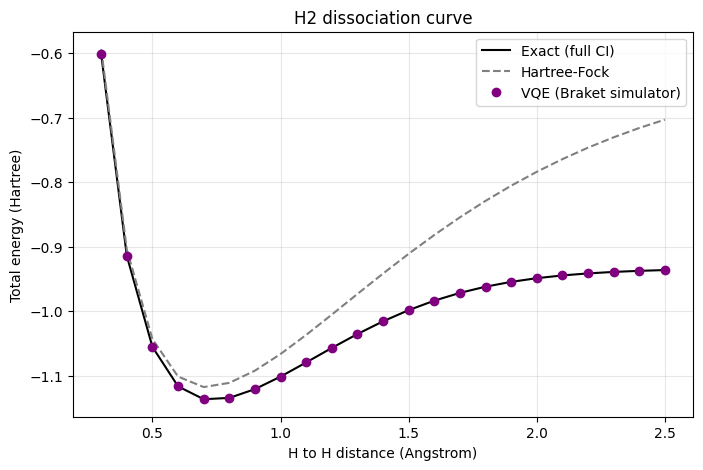

In [6]:
# Cell 6: run VQE at many bond lengths and plot the H2 energy curve
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from braket.circuits import Circuit, Observable
from braket.devices import LocalSimulator
from openfermion import MolecularData
from openfermion.transforms import get_fermion_operator, symmetry_conserving_bravyi_kitaev
from openfermionpyscf import run_pyscf

device = LocalSimulator()
paulis = {"I": np.eye(2), "X": np.array([[0, 1], [1, 0]]), "Z": np.array([[1, 0], [0, -1]])}
start_angles = {0: (0, 0), 1: (0, np.pi), 2: (np.pi, np.pi), 3: (np.pi, 0)}
observables = {
    "ZI": (Observable.Z(), [0]),
    "IZ": (Observable.Z(), [1]),
    "ZZ": (Observable.Z() @ Observable.Z(), [0, 1]),
    "XX": (Observable.X() @ Observable.X(), [0, 1]),
}

# Same circuit as Step 4
def build_circuit(params):
    circuit = Circuit()
    circuit.ry(0, params[0]); circuit.ry(1, params[1])
    circuit.cnot(0, 1)
    circuit.ry(0, params[2]); circuit.ry(1, params[3])
    return circuit

# Same Hamiltonian recipe as Step 2, wrapped in a function so we can reuse it for any distance
def build_hamiltonian(bond_length):
    geometry = [("H", (0, 0, 0)), ("H", (0, 0, bond_length))]
    molecule = MolecularData(geometry, "sto-3g", multiplicity=1, charge=0)
    molecule = run_pyscf(molecule, run_scf=1, run_fci=1)
    fermion_op = get_fermion_operator(molecule.get_molecular_hamiltonian())
    qubit_op = symmetry_conserving_bravyi_kitaev(fermion_op, active_orbitals=4, active_fermions=2)
    terms = {}
    for key, coeff in qubit_op.terms.items():
        label = ["I", "I"]
        for qubit, pauli in key:
            label[qubit] = pauli
        terms["".join(label)] = float(np.real(coeff))
    return molecule, terms

# Same energy measurement as Step 4
def energy(params, terms):
    circuit = build_circuit(params)
    names = [name for name in terms if name != "II"]
    for name in names:
        observable, target = observables[name]
        circuit.expectation(observable, target=target)
    result = device.run(circuit, shots=0).result()
    total = terms["II"]
    for name, value in zip(names, result.values):
        total += terms[name] * float(np.real(value))
    return total

# Same VQE loop as Step 4
def run_vqe(terms, hf_energy, seed=42):
    H = sum(c * np.kron(paulis[n[0]], paulis[n[1]]) for n, c in terms.items())
    hf_index = int(np.argmin(np.abs(np.diag(H) - hf_energy)))
    a0, a1 = start_angles[hf_index]
    rng = np.random.default_rng(seed)
    start = np.array([a0, a1, 0.0, 0.0]) + rng.normal(0, 0.15, 4)
    result = minimize(lambda p: energy(p, terms), start, method="COBYLA",
                      options={"maxiter": 200, "rhobeg": 0.4, "tol": 1e-8})
    return result.fun

# Loop over bond lengths from 0.3 to 2.5 Angstrom
bond_lengths = np.round(np.arange(0.3, 2.51, 0.1), 2)
distances, exact_list, hf_list, vqe_list = [], [], [], []

for r in bond_lengths:
    molecule, terms = build_hamiltonian(r)
    vqe_value = run_vqe(terms, molecule.hf_energy)
    distances.append(r)
    exact_list.append(molecule.fci_energy)
    hf_list.append(molecule.hf_energy)
    vqe_list.append(vqe_value)
    print(f"R = {r:.1f} A   exact = {molecule.fci_energy:.6f}   VQE = {vqe_value:.6f}   error = {abs(vqe_value - molecule.fci_energy):.1e}")

best = int(np.argmin(exact_list))
print(f"\nLowest energy: {exact_list[best]:.6f} Ha at {distances[best]:.1f} A")
print(f"Largest VQE error: {max(abs(np.array(vqe_list) - np.array(exact_list))):.1e} Ha")

# Plot
plt.figure(figsize=(8, 5))
plt.plot(distances, exact_list, "k-", label="Exact (full CI)")
plt.plot(distances, hf_list, "--", color="gray", label="Hartree-Fock")
plt.plot(distances, vqe_list, "o", color="purple", label="VQE (Braket simulator)")
plt.xlabel("H to H distance (Angstrom)")
plt.ylabel("Total energy (Hartree)")
plt.title("H2 dissociation curve")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("h2_curve.png", dpi=150, bbox_inches="tight")
plt.show()